# E-Commerce Sales & Customer Analytics Engine

## Python Mini Project

### Objective
The objective of this project is to build an end-to-end Python analytics engine that simulates, cleans, analyzes, and visualizes e-commerce sales and customer behavior data.

The project covers:
- Core Python
- NumPy
- File Handling and Exception Handling
- Pandas
- Data Cleaning and Exploratory Data Analysis (EDA)
- Matplotlib Data Visualization


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json


# Phase 1: Synthetic Data Generation & Utilities
## Core Python + NumPy

In this phase, synthetic e-commerce sales data is generated for 365 days across 3 store locations using NumPy.

In [ ]:
# Set random seed so we get the same random data every time
np.random.seed(42)

# Basic configuration
num_days = 365
num_stores = 3

store_names = np.array(["Store_A", "Store_B", "Store_C"])

print("Number of Days:", num_days)
print("Number of Stores:", num_stores)
print("Stores:", store_names)

Number of Days: 365
Number of Stores: 3
Stores: ['Store_A' 'Store_B' 'Store_C']


In [ ]:
# Generate synthetic sales data for 365 days across 3 stores

# Sales Amount - normally distributed
sales_amount = np.random.normal(
    loc=5000,
    scale=1200,
    size=(num_days, num_stores)
)

# Units Sold - random integers
units_sold = np.random.randint(
    20,
    150,
    size=(num_days, num_stores)
)

# Discount Percentage - between 0 and 0.5
discount_percentage = np.random.uniform(
    0,
    0.5,
    size=(num_days, num_stores)
)

# Customer Rating - between 1.0 and 5.0
customer_rating = np.random.uniform(
    1.0,
    5.0,
    size=(num_days, num_stores)
)

print("Sales Amount Shape:", sales_amount.shape)
print("Units Sold Shape:", units_sold.shape)
print("Discount Percentage Shape:", discount_percentage.shape)
print("Customer Rating Shape:", customer_rating.shape)

Sales Amount Shape: (365, 3)
Units Sold Shape: (365, 3)
Discount Percentage Shape: (365, 3)
Customer Rating Shape: (365, 3)


In [ ]:
# Create a 3D array: 12 Months x 30 Days x 3 Stores

monthly_sales_3d = np.random.normal(
    loc=5000,
    scale=1200,
    size=(12, 30, 3)
)

print("3D Sales Array Shape:", monthly_sales_3d.shape)
print("Number of Dimensions:", monthly_sales_3d.ndim)

3D Sales Array Shape: (12, 30, 3)
Number of Dimensions: 3


In [ ]:
# Initialize a baseline target board using np.zeros()

target_board = np.zeros((12, 3))

print("Target Board:")
print(target_board)

print("\nTarget Board Shape:", target_board.shape)

Target Board:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

Target Board Shape: (12, 3)


In [ ]:
# Convert Sales Amount data type to float32
sales_float32 = sales_amount.astype(np.float32)

print("Original Data Type:", sales_amount.dtype)
print("Converted Data Type:", sales_float32.dtype)

# Calculate basic statistics
mean_sales = np.mean(sales_amount)
std_sales = np.std(sales_amount)

print("\nMean Sales Amount:", round(mean_sales, 2))
print("Standard Deviation:", round(std_sales, 2))

Original Data Type: float64
Converted Data Type: float32

Mean Sales Amount: 5039.55
Standard Deviation: 1171.77


In [ ]:
# Reshape the Units Sold array

print("Original Shape:", units_sold.shape)

units_reshaped = units_sold.reshape(-1)

print("Reshaped Shape:", units_reshaped.shape)

# Transpose the Units Sold array

units_transposed = units_sold.T

print("Transposed Shape:", units_transposed.shape)

Original Shape: (365, 3)
Reshaped Shape: (1095,)
Transposed Shape: (3, 365)


### Core Python Concepts

This section demonstrates custom functions, flexible parameters, lambda functions, comprehensions, and Python data structures.

In [ ]:
# Custom revenue function using *args and **kwargs

def calculate_revenue(*sales, **options):
    total_revenue = sum(sales)

    discount = options.get("discount", 0)
    final_revenue = total_revenue * (1 - discount)

    return final_revenue


revenue = calculate_revenue(
    5000, 6500, 7200,
    discount=0.10
)

print("Final Revenue:", revenue)

Final Revenue: 16830.0


In [ ]:
# Product categories
categories = ["electronics", "fashion", "grocery", "beauty"]

# Lambda function
format_category = lambda name: name.upper()

formatted_categories = [format_category(category) for category in categories]

# Dictionary comprehension
category_ids = {
    category: index + 1
    for index, category in enumerate(formatted_categories)
}

print("Formatted Categories:", formatted_categories)
print("Category IDs:", category_ids)

Formatted Categories: ['ELECTRONICS', 'FASHION', 'GROCERY', 'BEAUTY']
Category IDs: {'ELECTRONICS': 1, 'FASHION': 2, 'GROCERY': 3, 'BEAUTY': 4}


In [ ]:
# List - product categories
product_categories = ["Electronics", "Fashion", "Grocery", "Beauty"]

# Tuple - fixed store locations
store_locations = ("Delhi", "Mumbai", "Bangalore")

# Set - unique categories
unique_categories = set(product_categories)

# Dictionary - store configuration
store_config = {
    "Store_A": "Delhi",
    "Store_B": "Mumbai",
    "Store_C": "Bangalore"
}

print("List:", product_categories)
print("Tuple:", store_locations)
print("Set:", unique_categories)
print("Dictionary:", store_config)

List: ['Electronics', 'Fashion', 'Grocery', 'Beauty']
Tuple: ('Delhi', 'Mumbai', 'Bangalore')
Set: {'Grocery', 'Fashion', 'Electronics', 'Beauty'}
Dictionary: {'Store_A': 'Delhi', 'Store_B': 'Mumbai', 'Store_C': 'Bangalore'}


# Phase 2: Data Ingestion, Storage & Exception Handling

In this phase, the generated sales data is stored in CSV and JSON files. Exception handling and control-flow techniques are also implemented to handle invalid or corrupted records.


In [ ]:
# Create dates for 365 days
dates = pd.date_range(start="2026-01-01", periods=num_days, freq="D")

# Convert generated arrays into tabular records
sales_records = []

for day in range(num_days):
    for store in range(num_stores):
        sales_records.append([
            dates[day],
            store_names[store],
            sales_amount[day, store],
            units_sold[day, store],
            discount_percentage[day, store],
            customer_rating[day, store]
        ])

# Save data using Python built-in file handling
with open("sales_data.csv", "w") as file:
    file.write(
        "Date,Store,Sales_Amount,Units_Sold,"
        "Discount_Percentage,Customer_Rating\n"
    )

    for record in sales_records:
        file.write(",".join(map(str, record)) + "\n")

print("sales_data.csv created successfully!")
print("Total Records:", len(sales_records))

sales_data.csv created successfully!
Total Records: 1095


In [ ]:
# Store metadata and category mappings

config_data = {
    "stores": {
        "Store_A": "Delhi",
        "Store_B": "Mumbai",
        "Store_C": "Bangalore"
    },

    "category_mapping": {
        "Electronics": 1,
        "Fashion": 2,
        "Grocery": 3,
        "Beauty": 4
    }
}

# Save configuration into JSON file
with open("store_config.json", "w") as file:
    json.dump(config_data, file, indent=4)

print("store_config.json created successfully!")

store_config.json created successfully!


### Exception Handling

The following section demonstrates robust file importing using try-except-else-finally blocks to handle possible errors such as FileNotFoundError, KeyError, and ValueError.

In [ ]:
# Robust data importer using exception handling

try:
    imported_data = pd.read_csv("sales_data.csv")

    # Check required column
    if "Sales_Amount" not in imported_data.columns:
        raise KeyError("Sales_Amount column is missing.")

    # Convert Sales Amount to numeric
    imported_data["Sales_Amount"] = pd.to_numeric(
        imported_data["Sales_Amount"]
    )

except FileNotFoundError:
    print("Error: sales_data.csv file was not found.")

except KeyError as e:
    print("Key Error:", e)

except ValueError as e:
    print("Value Error:", e)

else:
    print("Data imported successfully!")
    print("Dataset Shape:", imported_data.shape)

finally:
    print("Data import process completed.")

Data imported successfully!
Dataset Shape: (1095, 6)
Data import process completed.


In [ ]:
# Control flow demonstration

valid_records = []

for record in sales_records:

    sales = float(record[2])
    discount = float(record[4])
    rating = float(record[5])

    # Skip invalid sales records
    if sales <= 0:
        continue

    # Placeholder for unusually high sales
    if sales > 10000:
        pass

    # Store valid records
    if 0 <= discount <= 0.5 and 1 <= rating <= 5:
        valid_records.append(record)

print("Valid Records:", len(valid_records))


# Demonstrating while loop and break

counter = 0

while counter < len(valid_records):

    if counter == 5:
        break

    print("Checking Record:", counter + 1)
    counter += 1

Valid Records: 1095
Checking Record: 1
Checking Record: 2
Checking Record: 3
Checking Record: 4
Checking Record: 5


# Phase 3: Pandas Data Pipeline & Exploratory Data Analysis (EDA)

In this phase, the generated sales data is loaded into Pandas DataFrames for inspection, cleaning, manipulation, aggregation, and exploratory data analysis.

In [ ]:
# Load sales CSV into a Pandas DataFrame
df = pd.read_csv("sales_data.csv")

print("Dataset Shape:", df.shape)

# Display first 5 rows
df.head()

Dataset Shape: (1095, 6)


,Date,Store,Sales_Amount,Units_Sold,Discount_Percentage,Customer_Rating
0,2026-01-01 00:00:00,Store_A,5596.056984,88,0.343861,4.190929
1,2026-01-01 00:00:00,Store_B,4834.082839,31,0.361353,2.469563
2,2026-01-01 00:00:00,Store_C,5777.226246,39,0.346266,1.348069
3,2026-01-02 00:00:00,Store_A,6827.635828,62,0.067218,3.227140
4,2026-01-02 00:00:00,Store_B,4719.015950,145,0.149698,4.380483


In [ ]:
# Basic dataset inspection

print("Column Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nBasic Statistics:")
display(df.describe())

Column Names:
Index(['Date', 'Store', 'Sales_Amount', 'Units_Sold', 'Discount_Percentage',
       'Customer_Rating'],
      dtype='object')

Data Types:
Date                    object
Store                   object
Sales_Amount           float64
Units_Sold               int64
Discount_Percentage    float64
Customer_Rating        float64
dtype: object

Missing Values:
Date                   0
Store                  0
Sales_Amount           0
Units_Sold             0
Discount_Percentage    0
Customer_Rating        0
dtype: int64

Basic Statistics:


,Sales_Amount,Units_Sold,Discount_Percentage,Customer_Rating
count,1095.000000,1095.000000,1095.000000,1095.000000
mean,5039.547357,85.585388,0.248836,2.969637
std,1172.302982,38.160991,0.144330,1.142891
min,1110.479192,20.000000,0.000006,1.000123
25%,4258.707074,53.000000,0.124348,1.987031
50%,5045.604174,87.000000,0.250201,2.970142
75%,5786.551559,120.000000,0.373907,3.934303
max,9623.277789,149.000000,0.499446,4.998231


In [ ]:
# Creating DataFrame from a Python List

sample_list = [
    ["Store_A", "Electronics", 5000],
    ["Store_B", "Fashion", 4200],
    ["Store_C", "Grocery", 3800]
]

df_from_list = pd.DataFrame(
    sample_list,
    columns=["Store", "Category", "Sales"]
)

print("DataFrame created from List:")
display(df_from_list)


# Creating DataFrame from a Python Dictionary

sample_dict = {
    "Store": ["Store_A", "Store_B", "Store_C"],
    "Category": ["Electronics", "Fashion", "Grocery"],
    "Sales": [5000, 4200, 3800]
}

df_from_dict = pd.DataFrame(sample_dict)

print("DataFrame created from Dictionary:")
display(df_from_dict)

DataFrame created from List:


,Store,Category,Sales
0,Store_A,Electronics,5000
1,Store_B,Fashion,4200
2,Store_C,Grocery,3800


DataFrame created from Dictionary:


,Store,Category,Sales
0,Store_A,Electronics,5000
1,Store_B,Fashion,4200
2,Store_C,Grocery,3800


In [ ]:
# Create a Net Profit column
df["Net_Profit"] = df["Sales_Amount"] * (1 - df["Discount_Percentage"])

# Create another temporary column to demonstrate deletion
df["Temporary_Column"] = "Remove Me"

print("Columns after insertion:")
print(df.columns)

# Display first 5 rows
df.head()

Columns after insertion:
Index(['Date', 'Store', 'Sales_Amount', 'Units_Sold', 'Discount_Percentage',
       'Customer_Rating', 'Net_Profit', 'Temporary_Column'],
      dtype='object')


,Date,Store,Sales_Amount,Units_Sold,Discount_Percentage,Customer_Rating,Net_Profit,Temporary_Column
0,2026-01-01 00:00:00,Store_A,5596.056984,88,0.343861,4.190929,3671.791114,Remove Me
1,2026-01-01 00:00:00,Store_B,4834.082839,31,0.361353,2.469563,3087.270188,Remove Me
2,2026-01-01 00:00:00,Store_C,5777.226246,39,0.346266,1.348069,3776.767976,Remove Me
3,2026-01-02 00:00:00,Store_A,6827.635828,62,0.067218,3.227140,6368.698775,Remove Me
4,2026-01-02 00:00:00,Store_B,4719.015950,145,0.149698,4.380483,4012.589672,Remove Me


In [ ]:
# Delete the temporary column
df.drop("Temporary_Column", axis=1, inplace=True)

print("Columns after deletion:")
print(df.columns)

df.head()

Columns after deletion:
Index(['Date', 'Store', 'Sales_Amount', 'Units_Sold', 'Discount_Percentage',
       'Customer_Rating', 'Net_Profit'],
      dtype='object')


,Date,Store,Sales_Amount,Units_Sold,Discount_Percentage,Customer_Rating,Net_Profit
0,2026-01-01 00:00:00,Store_A,5596.056984,88,0.343861,4.190929,3671.791114
1,2026-01-01 00:00:00,Store_B,4834.082839,31,0.361353,2.469563,3087.270188
2,2026-01-01 00:00:00,Store_C,5777.226246,39,0.346266,1.348069,3776.767976
3,2026-01-02 00:00:00,Store_A,6827.635828,62,0.067218,3.227140,6368.698775
4,2026-01-02 00:00:00,Store_B,4719.015950,145,0.149698,4.380483,4012.589672


In [ ]:
# Inject approximately 5% missing values into Sales_Amount

np.random.seed(42)

missing_indices = np.random.choice(
    df.index,
    size=int(0.05 * len(df)),
    replace=False
)

df.loc[missing_indices, "Sales_Amount"] = np.nan

print("Missing values before handling:")
print(df.isnull().sum())

Missing values before handling:
Date                    0
Store                   0
Sales_Amount           54
Units_Sold              0
Discount_Percentage     0
Customer_Rating         0
Net_Profit              0
dtype: int64


In [ ]:
# Calculate median of Sales_Amount
sales_median = df["Sales_Amount"].median()

# Fill missing values with median
df["Sales_Amount"] = df["Sales_Amount"].fillna(sales_median)

print("Median Sales Amount:", round(sales_median, 2))

print("\nMissing values after handling:")
print(df.isnull().sum())

Median Sales Amount: 5054.69

Missing values after handling:
Date                   0
Store                  0
Sales_Amount           0
Units_Sold             0
Discount_Percentage    0
Customer_Rating        0
Net_Profit             0
dtype: int64


In [ ]:
# Add some duplicate records for demonstration
df = pd.concat([df, df.iloc[:5]], ignore_index=True)

# Detect duplicates
duplicate_count = df.duplicated().sum()

print("Duplicate records found:", duplicate_count)

# Remove duplicate records
df.drop_duplicates(inplace=True)

print("Duplicates after removal:", df.duplicated().sum())
print("Dataset shape after removing duplicates:", df.shape)

Duplicate records found: 5
Duplicates after removal: 0
Dataset shape after removing duplicates: (1095, 7)


In [ ]:
# Calculate Q1 and Q3
Q1 = df["Sales_Amount"].quantile(0.25)
Q3 = df["Sales_Amount"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Define lower and upper limits
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

# Find outliers
outliers = df[
    (df["Sales_Amount"] < lower_bound) |
    (df["Sales_Amount"] > upper_bound)
]

print("\nNumber of Outliers:", len(outliers))

Q1: 4310.4
Q3: 5760.11
IQR: 1449.71
Lower Bound: 2135.83
Upper Bound: 7934.68

Number of Outliers: 17


In [ ]:
# Remove Sales Amount outliers using IQR boundaries

df_clean = df[
    (df["Sales_Amount"] >= lower_bound) &
    (df["Sales_Amount"] <= upper_bound)
].copy()

print("Original Dataset Size:", len(df))
print("Outliers Removed:", len(df) - len(df_clean))
print("Clean Dataset Size:", len(df_clean))

Original Dataset Size: 1095
Outliers Removed: 17
Clean Dataset Size: 1078


In [ ]:
df = df_clean.reset_index(drop=True)

print("Final Clean Dataset Shape:", df.shape)

Final Clean Dataset Shape: (1078, 7)


In [ ]:
# Convert Date column to datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Extract date-time features
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.day_name()

print("Date-Time Features Added:")
df[["Date", "Month", "Day", "DayOfWeek"]].head()

Date-Time Features Added:


,Date,Month,Day,DayOfWeek
0,2026-01-01,1,1,Thursday
1,2026-01-01,1,1,Thursday
2,2026-01-01,1,1,Thursday
3,2026-01-02,1,2,Friday
4,2026-01-02,1,2,Friday


In [ ]:
# Calculate monthly sales using time-based resampling

monthly_sales = (
    df.set_index("Date")
      .resample("ME")["Sales_Amount"]
      .sum()
)

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
Date
2026-01-31    455583.870465
2026-02-28    412904.540643
2026-03-31    451321.536362
2026-04-30    454940.446340
2026-05-31    468574.087702
2026-06-30    426642.469432
2026-07-31    460588.710563
2026-08-31    444104.209585
2026-09-30    437670.916118
2026-10-31    480094.621878
2026-11-30    451253.191319
2026-12-31    482748.243528
Freq: ME, Name: Sales_Amount, dtype: float64


In [ ]:
# Create store metadata DataFrame

store_metadata = pd.DataFrame({
    "Store": ["Store_A", "Store_B", "Store_C"],
    "Location": ["Delhi", "Mumbai", "Bangalore"],
    "Store_Type": ["Urban", "Urban", "Urban"]
})

print("Store Metadata:")
display(store_metadata)

Store Metadata:


,Store,Location,Store_Type
0,Store_A,Delhi,Urban
1,Store_B,Mumbai,Urban
2,Store_C,Bangalore,Urban


In [ ]:
# Merge sales dataset with store metadata

df = pd.merge(
    df,
    store_metadata,
    on="Store",
    how="left"
)

print("Dataset after Merge:")
display(df.head())

print("\nNew Dataset Shape:", df.shape)

Dataset after Merge:


,Date,Store,Sales_Amount,Units_Sold,Discount_Percentage,Customer_Rating,Net_Profit,Month,Day,DayOfWeek,Location,Store_Type
0,2026-01-01,Store_A,5596.056984,88,0.343861,4.190929,3671.791114,1,1,Thursday,Delhi,Urban
1,2026-01-01,Store_B,4834.082839,31,0.361353,2.469563,3087.270188,1,1,Thursday,Mumbai,Urban
2,2026-01-01,Store_C,5777.226246,39,0.346266,1.348069,3776.767976,1,1,Thursday,Bangalore,Urban
3,2026-01-02,Store_A,6827.635828,62,0.067218,3.227140,6368.698775,1,2,Friday,Delhi,Urban
4,2026-01-02,Store_B,4719.015950,145,0.149698,4.380483,4012.589672,1,2,Friday,Mumbai,Urban



New Dataset Shape: (1078, 12)


In [ ]:
# Demonstrate concatenation

first_half = df.iloc[:5]
second_half = df.iloc[5:10]

combined_sample = pd.concat(
    [first_half, second_half],
    ignore_index=True
)

print("Concatenated Sample:")
display(combined_sample)

Concatenated Sample:


,Date,Store,Sales_Amount,Units_Sold,Discount_Percentage,Customer_Rating,Net_Profit,Month,Day,DayOfWeek,Location,Store_Type
0,2026-01-01,Store_A,5596.056984,88,0.343861,4.190929,3671.791114,1,1,Thursday,Delhi,Urban
1,2026-01-01,Store_B,4834.082839,31,0.361353,2.469563,3087.270188,1,1,Thursday,Mumbai,Urban
2,2026-01-01,Store_C,5777.226246,39,0.346266,1.348069,3776.767976,1,1,Thursday,Bangalore,Urban
3,2026-01-02,Store_A,6827.635828,62,0.067218,3.227140,6368.698775,1,2,Friday,Delhi,Urban
4,2026-01-02,Store_B,4719.015950,145,0.149698,4.380483,4012.589672,1,2,Friday,Mumbai,Urban
5,2026-01-02,Store_C,4719.035652,69,0.179358,4.183706,3872.639975,1,2,Friday,Bangalore,Urban
6,2026-01-03,Store_A,6895.055379,48,0.402219,1.700493,4121.735831,1,3,Saturday,Delhi,Urban
7,2026-01-03,Store_B,5920.921675,58,0.139380,3.691058,5095.663990,1,3,Saturday,Mumbai,Urban
8,2026-01-03,Store_C,4436.630737,57,0.105352,1.882017,3969.220677,1,3,Saturday,Bangalore,Urban
9,2026-01-04,Store_A,5651.072052,103,0.478724,1.872830,2945.768181,1,4,Sunday,Delhi,Urban


In [ ]:
# Average sales and units sold by store

store_summary = df.groupby("Store").agg({
    "Sales_Amount": "mean",
    "Units_Sold": "mean",
    "Net_Profit": "mean"
}).round(2)

print("Average Performance by Store:")
display(store_summary)

Average Performance by Store:


,Sales_Amount,Units_Sold,Net_Profit
Store,,,
Store_A,5066.00,84.61,3840.39
Store_B,4961.86,85.43,3734.54
Store_C,5073.49,87.04,3747.87


In [ ]:
# Monthly sales summary

monthly_summary = df.groupby("Month").agg({
    "Sales_Amount": "sum",
    "Units_Sold": "sum",
    "Net_Profit": "sum"
}).round(2)

print("Monthly Sales Summary:")
display(monthly_summary)

Monthly Sales Summary:


,Sales_Amount,Units_Sold,Net_Profit
Month,,,
1,455583.87,7840,343374.43
2,412904.54,7122,315725.01
3,451321.54,7108,339978.92
4,454940.45,7777,335215.24
5,468574.09,7561,344739.04
6,426642.47,7920,320620.99
7,460588.71,8336,348401.11
8,444104.21,7641,338817.47
9,437670.92,7592,328829.10


In [ ]:
# Add Product Category to the dataset

np.random.seed(42)

categories = ["Electronics", "Fashion", "Grocery", "Beauty"]

df["Category"] = np.random.choice(
    categories,
    size=len(df)
)

print("Product Categories Added:")
print(df["Category"].value_counts())

df.head()

Product Categories Added:
Category
Electronics    291
Beauty         289
Grocery        250
Fashion        248
Name: count, dtype: int64


,Date,Store,Sales_Amount,Units_Sold,Discount_Percentage,Customer_Rating,Net_Profit,Month,Day,DayOfWeek,Location,Store_Type,Category
0,2026-01-01,Store_A,5596.056984,88,0.343861,4.190929,3671.791114,1,1,Thursday,Delhi,Urban,Grocery
1,2026-01-01,Store_B,4834.082839,31,0.361353,2.469563,3087.270188,1,1,Thursday,Mumbai,Urban,Beauty
2,2026-01-01,Store_C,5777.226246,39,0.346266,1.348069,3776.767976,1,1,Thursday,Bangalore,Urban,Electronics
3,2026-01-02,Store_A,6827.635828,62,0.067218,3.227140,6368.698775,1,2,Friday,Delhi,Urban,Grocery
4,2026-01-02,Store_B,4719.015950,145,0.149698,4.380483,4012.589672,1,2,Friday,Mumbai,Urban,Grocery


In [ ]:
# Average sales and units sold by product category

category_summary = df.groupby("Category").agg({
    "Sales_Amount": "mean",
    "Units_Sold": "mean",
    "Net_Profit": "mean"
}).round(2)

print("Average Performance by Product Category:")
display(category_summary)

Average Performance by Product Category:


,Sales_Amount,Units_Sold,Net_Profit
Category,,,
Beauty,4935.85,86.21,3676.91
Electronics,5045.26,83.76,3797.49
Fashion,5157.50,84.81,3856.72
Grocery,5010.95,88.19,3779.36


In [ ]:
# Demonstrate NumPy sorting

sample_sales = sales_amount[0]

print("Original Sales Values:")
print(sample_sales)

sorted_sales = np.sort(sample_sales)

print("\nSorted Sales Values:")
print(sorted_sales)

Original Sales Values:
[5596.05698361 4834.08283859 5777.22624572]

Sorted Sales Values:
[4834.08283859 5596.05698361 5777.22624572]


# Phase 4: Data Visualization Dashboard

This phase visualizes the cleaned e-commerce dataset using Matplotlib. The dashboard includes line, bar, scatter, histogram, pie, and 3D plots to analyze sales and customer behavior.


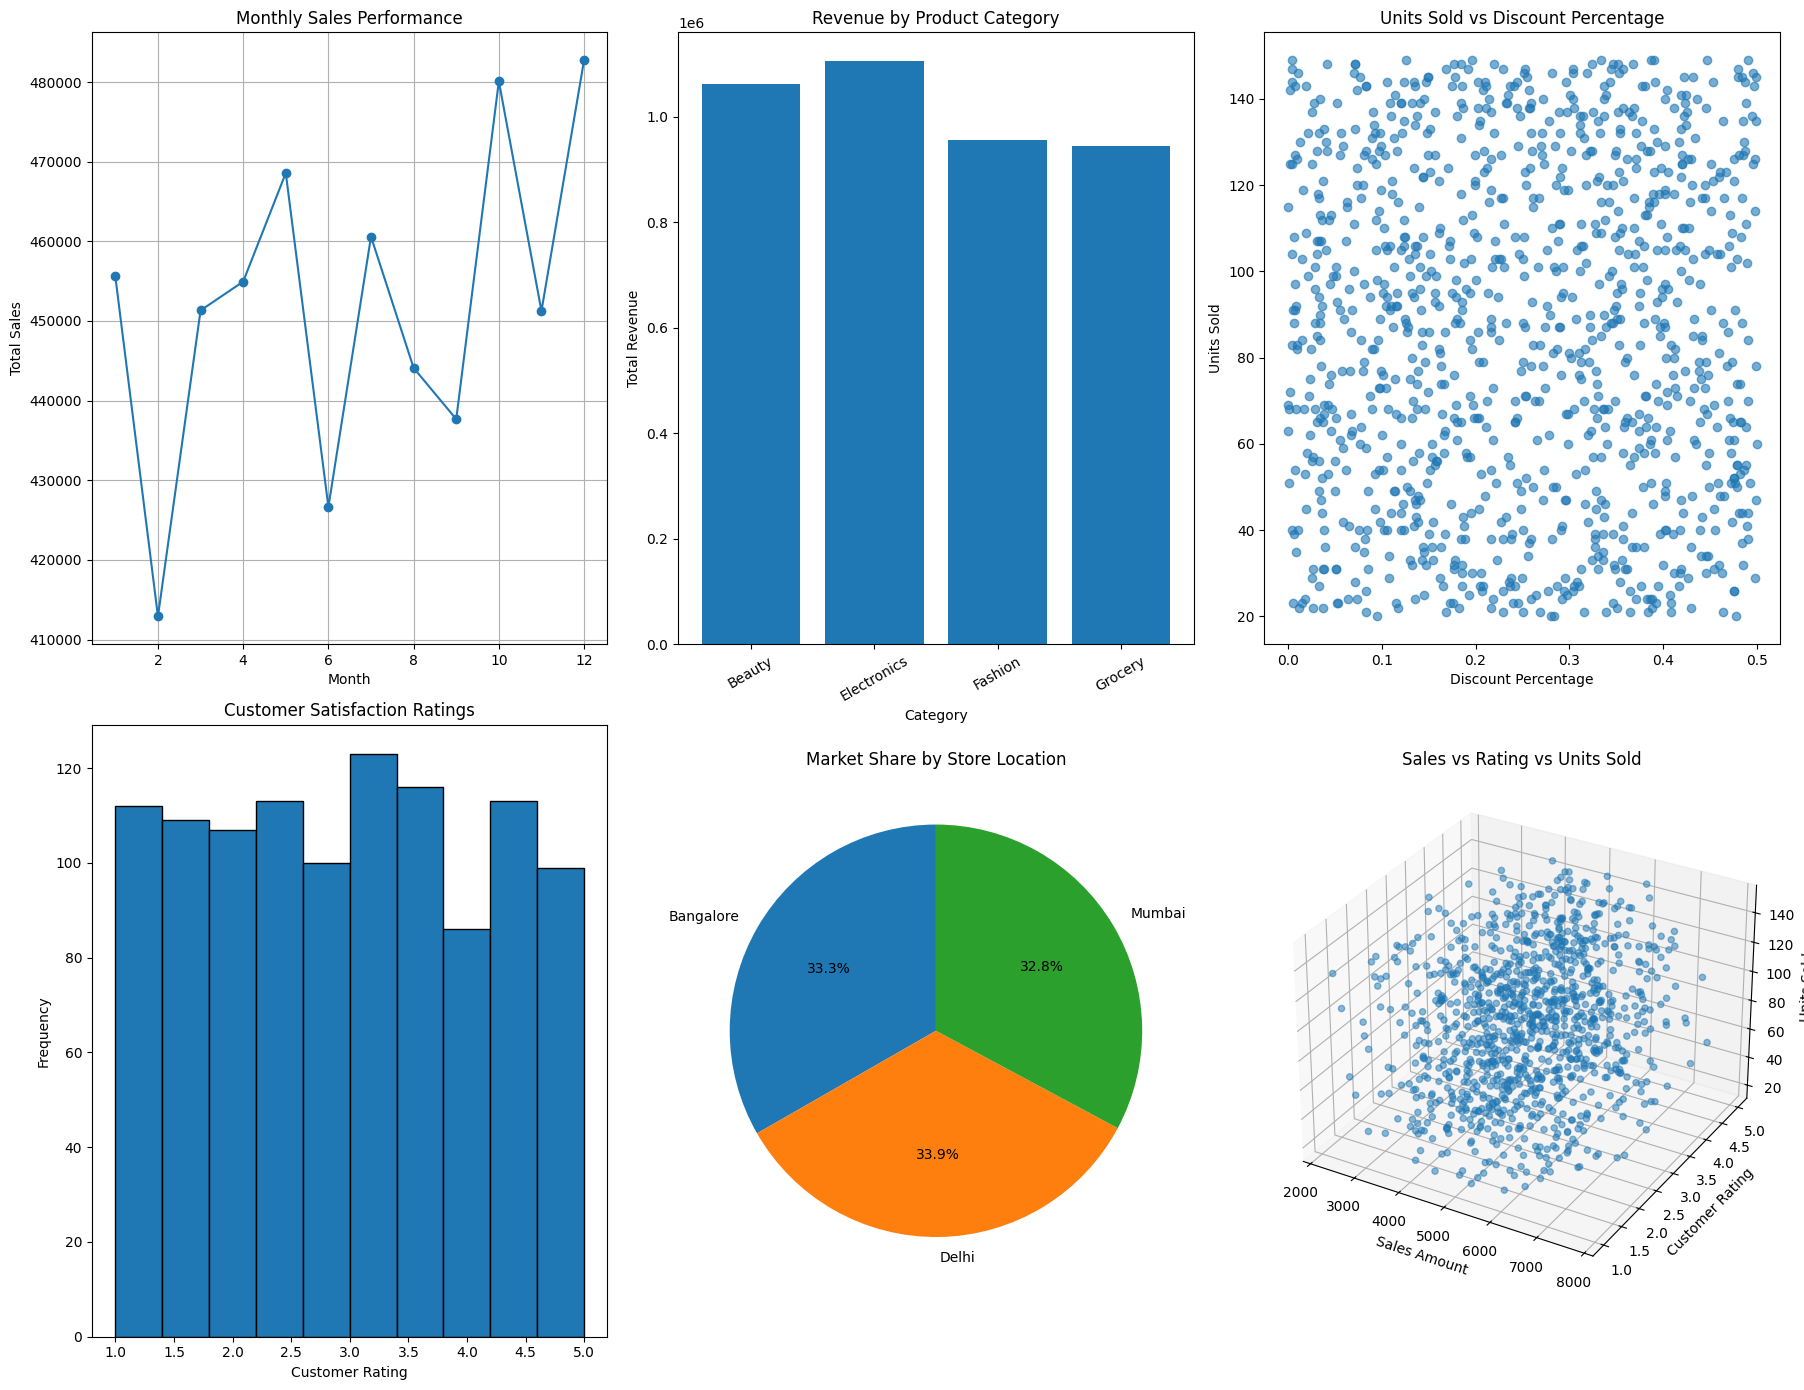

Dashboard saved successfully as dashboard.png


In [ ]:
# Prepare data for visualizations

# 1. Monthly sales
monthly_plot = df.groupby("Month")["Sales_Amount"].sum()

# 2. Revenue by category
category_revenue = df.groupby("Category")["Net_Profit"].sum()

# 3. Market share by store location
location_sales = df.groupby("Location")["Sales_Amount"].sum()


# Create dashboard
fig = plt.figure(figsize=(18, 14))

# 1. Line Plot - Monthly Sales
ax1 = fig.add_subplot(2, 3, 1)
ax1.plot(monthly_plot.index, monthly_plot.values, marker="o")
ax1.set_title("Monthly Sales Performance")
ax1.set_xlabel("Month")
ax1.set_ylabel("Total Sales")
ax1.grid(True)


# 2. Bar Plot - Revenue by Product Category
ax2 = fig.add_subplot(2, 3, 2)
ax2.bar(category_revenue.index, category_revenue.values)
ax2.set_title("Revenue by Product Category")
ax2.set_xlabel("Category")
ax2.set_ylabel("Total Revenue")
ax2.tick_params(axis="x", rotation=30)


# 3. Scatter Plot - Units Sold vs Discount
ax3 = fig.add_subplot(2, 3, 3)
ax3.scatter(
    df["Discount_Percentage"],
    df["Units_Sold"],
    alpha=0.6
)
ax3.set_title("Units Sold vs Discount Percentage")
ax3.set_xlabel("Discount Percentage")
ax3.set_ylabel("Units Sold")


# 4. Histogram - Customer Ratings
ax4 = fig.add_subplot(2, 3, 4)
ax4.hist(
    df["Customer_Rating"],
    bins=10,
    edgecolor="black"
)
ax4.set_title("Customer Satisfaction Ratings")
ax4.set_xlabel("Customer Rating")
ax4.set_ylabel("Frequency")


# 5. Pie Chart - Market Share by Store Location
ax5 = fig.add_subplot(2, 3, 5)
ax5.pie(
    location_sales.values,
    labels=location_sales.index,
    autopct="%1.1f%%",
    startangle=90
)
ax5.set_title("Market Share by Store Location")


# 6. 3D Scatter Plot
ax6 = fig.add_subplot(2, 3, 6, projection="3d")

ax6.scatter(
    df["Sales_Amount"],
    df["Customer_Rating"],
    df["Units_Sold"],
    alpha=0.5
)

ax6.set_title("Sales vs Rating vs Units Sold")
ax6.set_xlabel("Sales Amount")
ax6.set_ylabel("Customer Rating")
ax6.set_zlabel("Units Sold")


# Improve layout
plt.tight_layout()

# Save dashboard
plt.savefig(
    "dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved successfully as dashboard.png")

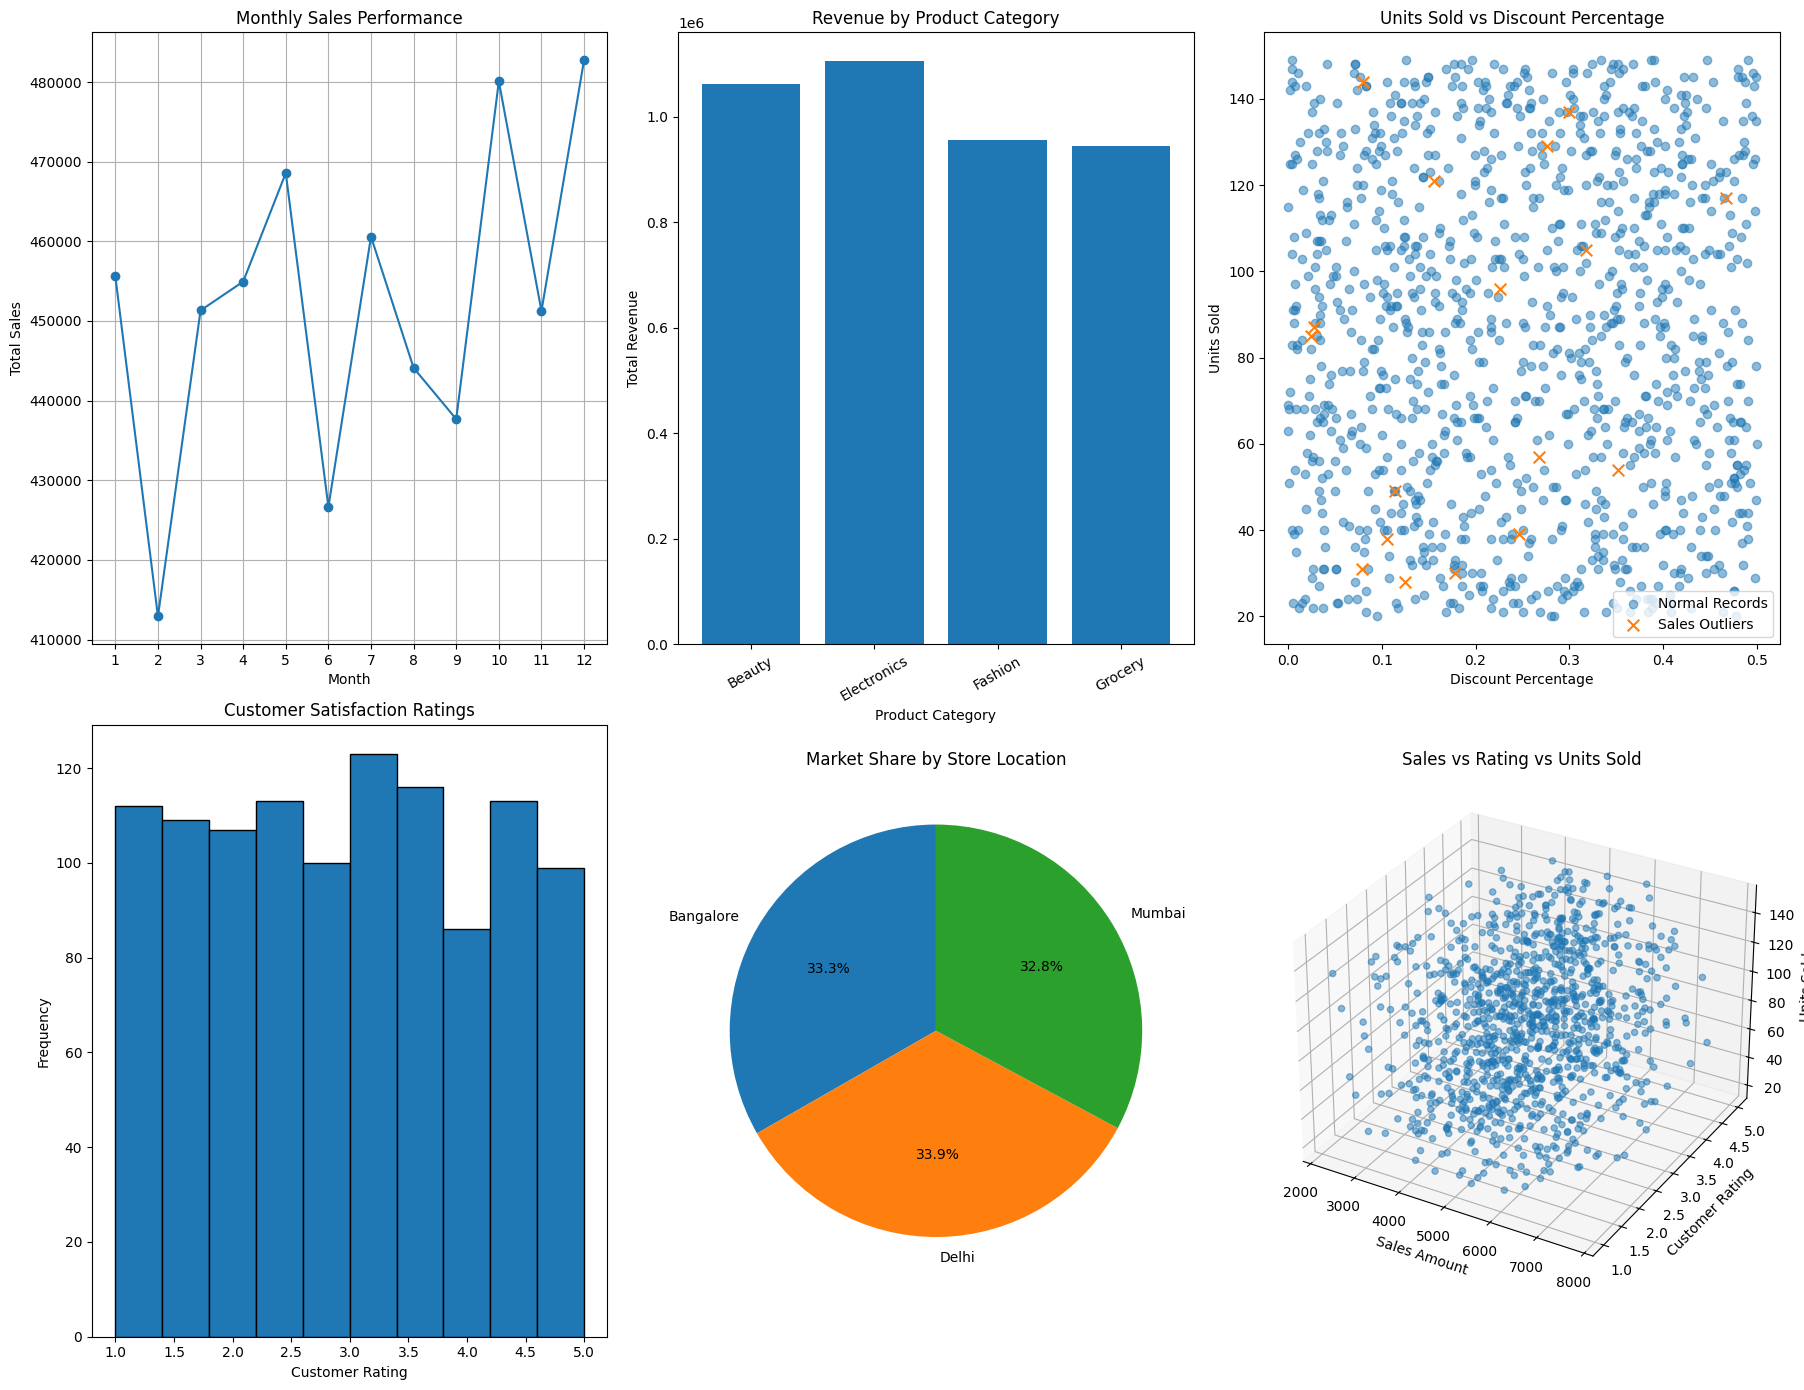

Dashboard saved successfully as dashboard.png


In [ ]:
# ============================================================
# PHASE 4: DATA VISUALIZATION DASHBOARD
# ============================================================

# Prepare data for visualizations

# 1. Monthly Sales
monthly_plot = df.groupby("Month")["Sales_Amount"].sum()

# 2. Revenue by Product Category
category_revenue = df.groupby("Category")["Net_Profit"].sum()

# 3. Market Share by Store Location
location_sales = df.groupby("Location")["Sales_Amount"].sum()


# ============================================================
# CREATE DASHBOARD
# ============================================================

fig = plt.figure(figsize=(18, 14))


# ------------------------------------------------------------
# 1. LINE PLOT - Monthly Sales Performance
# ------------------------------------------------------------

ax1 = fig.add_subplot(2, 3, 1)

ax1.plot(
    monthly_plot.index,
    monthly_plot.values,
    marker="o"
)

ax1.set_title("Monthly Sales Performance")
ax1.set_xlabel("Month")
ax1.set_ylabel("Total Sales")
ax1.set_xticks(range(1, 13))
ax1.grid(True)


# ------------------------------------------------------------
# 2. BAR PLOT - Revenue by Product Category
# ------------------------------------------------------------

ax2 = fig.add_subplot(2, 3, 2)

ax2.bar(
    category_revenue.index,
    category_revenue.values
)

ax2.set_title("Revenue by Product Category")
ax2.set_xlabel("Product Category")
ax2.set_ylabel("Total Revenue")

ax2.tick_params(
    axis="x",
    rotation=30
)


# ------------------------------------------------------------
# 3. SCATTER PLOT - Units Sold vs Discount Percentage
#    with detected Sales Outliers highlighted
# ------------------------------------------------------------

ax3 = fig.add_subplot(2, 3, 3)

# Normal cleaned records
ax3.scatter(
    df["Discount_Percentage"],
    df["Units_Sold"],
    alpha=0.5,
    label="Normal Records"
)

# Previously detected Sales Amount outliers
ax3.scatter(
    outliers["Discount_Percentage"],
    outliers["Units_Sold"],
    marker="x",
    s=70,
    label="Sales Outliers"
)

ax3.set_title("Units Sold vs Discount Percentage")
ax3.set_xlabel("Discount Percentage")
ax3.set_ylabel("Units Sold")
ax3.legend()


# ------------------------------------------------------------
# 4. HISTOGRAM - Customer Satisfaction Ratings
# ------------------------------------------------------------

ax4 = fig.add_subplot(2, 3, 4)

ax4.hist(
    df["Customer_Rating"],
    bins=10,
    edgecolor="black"
)

ax4.set_title("Customer Satisfaction Ratings")
ax4.set_xlabel("Customer Rating")
ax4.set_ylabel("Frequency")


# ------------------------------------------------------------
# 5. PIE CHART - Market Share by Store Location
# ------------------------------------------------------------

ax5 = fig.add_subplot(2, 3, 5)

ax5.pie(
    location_sales.values,
    labels=location_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

ax5.set_title("Market Share by Store Location")


# ------------------------------------------------------------
# 6. 3D SCATTER PLOT
# Sales Amount vs Customer Rating vs Units Sold
# ------------------------------------------------------------

ax6 = fig.add_subplot(
    2,
    3,
    6,
    projection="3d"
)

ax6.scatter(
    df["Sales_Amount"],
    df["Customer_Rating"],
    df["Units_Sold"],
    alpha=0.5
)

ax6.set_title("Sales vs Rating vs Units Sold")
ax6.set_xlabel("Sales Amount")
ax6.set_ylabel("Customer Rating")
ax6.set_zlabel("Units Sold")


# ============================================================
# FINAL DASHBOARD SETTINGS
# ============================================================

plt.tight_layout()

# Save dashboard as high-resolution PNG
plt.savefig(
    "dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved successfully as dashboard.png")

In [ ]:
# Load store_config.json into a Pandas DataFrame

with open("store_config.json", "r") as file:
    json_data = json.load(file)

store_config_df = pd.DataFrame(
    list(json_data["stores"].items()),
    columns=["Store", "Location"]
)

print("Store Configuration DataFrame:")
display(store_config_df)

Store Configuration DataFrame:


,Store,Location
0,Store_A,Delhi
1,Store_B,Mumbai
2,Store_C,Bangalore


In [ ]:
# Demonstration of 1D, 2D and 3D NumPy Arrays

# 1D Array
array_1d = np.array([1000, 2000, 3000, 4000, 5000])

# 2D Array
array_2d = sales_amount

# 3D Array
array_3d = monthly_sales_3d

print("1D Array Shape:", array_1d.shape)
print("2D Array Shape:", array_2d.shape)
print("3D Array Shape:", array_3d.shape)

print("\nNumber of Dimensions:")
print("1D Array:", array_1d.ndim)
print("2D Array:", array_2d.ndim)
print("3D Array:", array_3d.ndim)

1D Array Shape: (5,)
2D Array Shape: (365, 3)
3D Array Shape: (12, 30, 3)

Number of Dimensions:
1D Array: 1
2D Array: 2
3D Array: 3


# Project Summary

The E-Commerce Sales & Customer Analytics Engine demonstrates an end-to-end Python data analytics workflow.

The project includes:

- Synthetic e-commerce data generation using NumPy.
- Implementation of Python data structures, functions, comprehensions, loops, and exception handling.
- CSV and JSON file handling.
- Data loading and manipulation using Pandas.
- Missing value treatment, duplicate removal, and IQR-based outlier detection.
- Date-time feature extraction and time-based resampling.
- Dataset merging and aggregation using GroupBy.
- Product category, store, and monthly sales analysis.
- A Matplotlib dashboard containing line, bar, scatter, histogram, pie, and 3D visualizations.
- Export of the final dashboard as a high-resolution PNG image.

This project demonstrates the complete workflow from raw synthetic data generation to cleaning, exploratory analysis, aggregation, visualization, and reporting.